In [ ]:
# CodeAlpha Internship — Credit Scoring Model

## Task 1: Credit Scoring Model Using Machine Learning

### Objective

The objective of this project is to predict an individual's creditworthiness
using past financial data.

The project will include:

- Creating and preparing financial data
- Data exploration
- Feature engineering
- Data preprocessing
- Training a classification model
- Model evaluation
- Precision, Recall, F1-Score
- ROC-AUC analysis
- Confusion Matrix
- Prediction for a new customer

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    "Income": [
        45000, 60000, 35000, 80000, 55000,
        30000, 90000, 40000, 70000, 50000,
        25000, 75000, 65000, 32000, 85000,
        48000, 58000, 42000, 95000, 37000,
        68000, 29000, 72000, 53000, 61000,
        33000, 88000, 46000, 79000, 41000
    ],

    "Debt": [
        10000, 12000, 18000, 15000, 11000,
        22000, 10000, 19000, 13000, 14000,
        25000, 12000, 14000, 21000, 9000,
        16000, 11000, 20000, 8000, 23000,
        13000, 24000, 10000, 15000, 12000,
        20000, 11000, 17000, 9000, 22000
    ],

    "Payment_History": [
        90, 95, 70, 98, 88,
        60, 99, 65, 92, 85,
        55, 96, 90, 62, 97,
        80, 94, 68, 99, 58,
        93, 52, 95, 86, 91,
        64, 98, 78, 96, 61
    ],

    "Credit_Utilization": [
        25, 20, 55, 18, 30,
        70, 15, 60, 22, 35,
        80, 19, 28, 65, 12,
        40, 24, 58, 10, 75,
        26, 85, 17, 32, 23,
        68, 14, 45, 16, 72
    ],

    "Creditworthy": [
        1, 1, 0, 1, 1,
        0, 1, 0, 1, 1,
        0, 1, 1, 0, 1,
        1, 1, 0, 1, 0,
        1, 0, 1, 1, 1,
        0, 1, 1, 1, 0
    ]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset created successfully!
Rows: 30
Columns: 5


In [3]:
df.head()

,Income,Debt,Payment_History,Credit_Utilization,Creditworthy
0,45000,10000,90,25,1
1,60000,12000,95,20,1
2,35000,18000,70,55,0
3,80000,15000,98,18,1
4,55000,11000,88,30,1


In [4]:
df.describe()

,Income,Debt,Payment_History,Credit_Utilization,Creditworthy
count,30.000000,30.000000,30.000000,30.000000,30.000000
mean,56233.333333,15200.000000,81.833333,38.633333,0.666667
std,20349.842554,5047.361892,15.737246,23.590593,0.479463
min,25000.000000,8000.000000,52.000000,10.000000,0.000000
25%,40250.000000,11000.000000,65.750000,19.250000,0.000000
50%,54000.000000,14000.000000,89.000000,29.000000,1.000000
75%,71500.000000,19750.000000,95.000000,59.500000,1.000000
max,95000.000000,25000.000000,99.000000,85.000000,1.000000


In [5]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Income                0
Debt                  0
Payment_History       0
Credit_Utilization    0
Creditworthy          0
dtype: int64


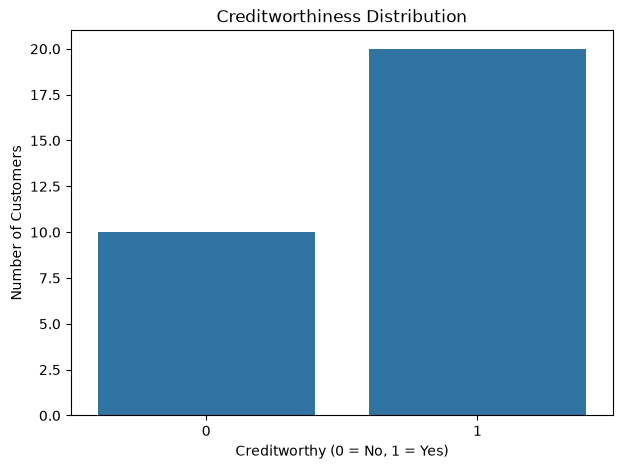

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Creditworthy"
)

plt.title("Creditworthiness Distribution")
plt.xlabel("Creditworthy (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

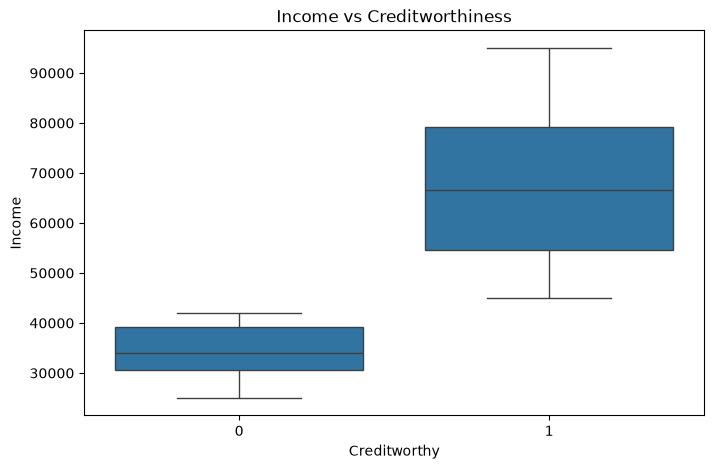

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Creditworthy",
    y="Income"
)

plt.title("Income vs Creditworthiness")
plt.xlabel("Creditworthy")
plt.ylabel("Income")

plt.show()

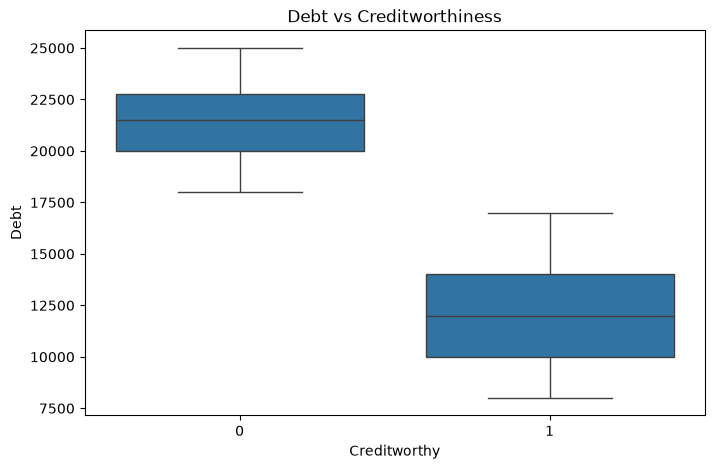

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Creditworthy",
    y="Debt"
)

plt.title("Debt vs Creditworthiness")
plt.xlabel("Creditworthy")
plt.ylabel("Debt")

plt.show()

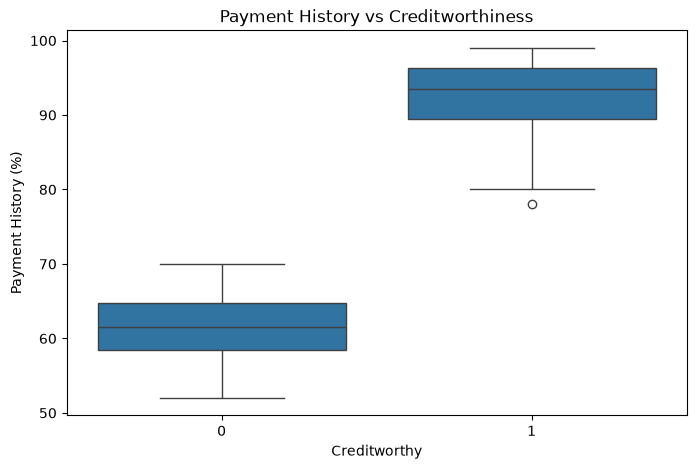

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Creditworthy",
    y="Payment_History"
)

plt.title("Payment History vs Creditworthiness")
plt.xlabel("Creditworthy")
plt.ylabel("Payment History (%)")

plt.show()

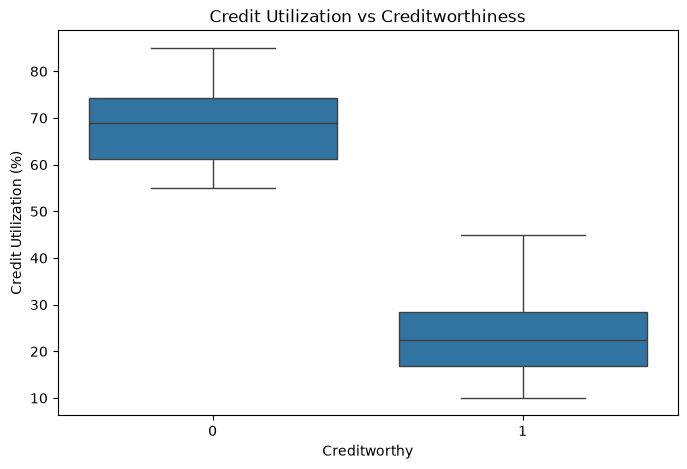

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Creditworthy",
    y="Credit_Utilization"
)

plt.title("Credit Utilization vs Creditworthiness")
plt.xlabel("Creditworthy")
plt.ylabel("Credit Utilization (%)")

plt.show()

In [11]:
correlation = df.corr()

correlation

,Income,Debt,Payment_History,Credit_Utilization,Creditworthy
Income,1.000000,-0.848833,0.901252,-0.902064,0.771624
Debt,-0.848833,1.000000,-0.957667,0.967901,-0.883434
Payment_History,0.901252,-0.957667,1.000000,-0.995593,0.929237
Credit_Utilization,-0.902064,0.967901,-0.995593,1.000000,-0.919677
Creditworthy,0.771624,-0.883434,0.929237,-0.919677,1.000000


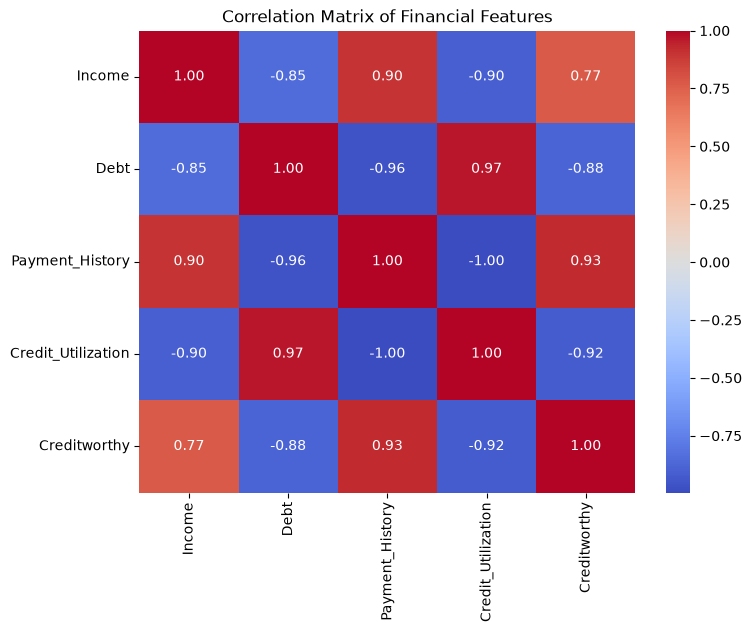

In [12]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Financial Features")

plt.show()

In [13]:
X = df.drop("Creditworthy", axis=1)
y = df["Creditworthy"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Income   Debt  Payment_History  Credit_Utilization
0   45000  10000               90                  25
1   60000  12000               95                  20
2   35000  18000               70                  55
3   80000  15000               98                  18
4   55000  11000               88                  30

Target:
0    1
1    1
2    0
3    1
4    1
Name: Creditworthy, dtype: int64


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 24
Testing samples: 6


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [16]:
model = LogisticRegression()

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [17]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Predicted classes:")
print(y_pred)

print("\nPrediction probabilities:")
print(y_prob)

Predicted classes:
[0 1 1 1 0 1]

Prediction probabilities:
[0.00660951 0.51950769 0.93997714 0.99328862 0.02088223 0.66003454]


In [18]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 100.00%


In [19]:
precision = precision_score(y_test, y_pred)

print(f"Precision: {precision:.2f}")

Precision: 1.00


In [20]:
recall = recall_score(y_test, y_pred)

print(f"Recall: {recall:.2f}")

Recall: 1.00


In [21]:
f1 = f1_score(y_test, y_pred)

print(f"F1-Score: {f1:.2f}")


F1-Score: 1.00


In [22]:
roc_auc = roc_auc_score(y_test, y_prob)

print(f"ROC-AUC Score: {roc_auc:.2f}")

ROC-AUC Score: 1.00


In [23]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Creditworthy", "Creditworthy"]
    )
)

Classification Report:

                  precision    recall  f1-score   support

Not Creditworthy       1.00      1.00      1.00         2
    Creditworthy       1.00      1.00      1.00         4

        accuracy                           1.00         6
       macro avg       1.00      1.00      1.00         6
    weighted avg       1.00      1.00      1.00         6



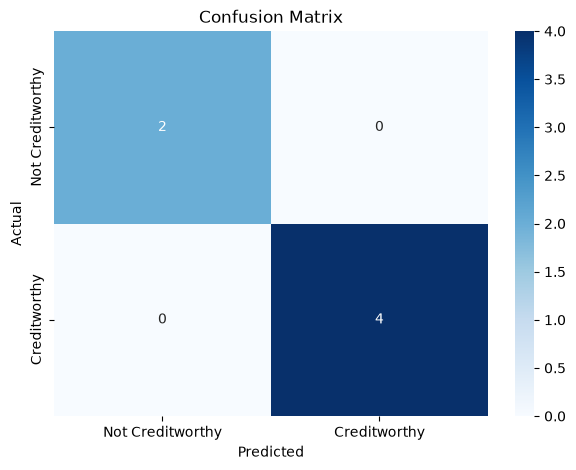

In [24]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Creditworthy", "Creditworthy"],
    yticklabels=["Not Creditworthy", "Creditworthy"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

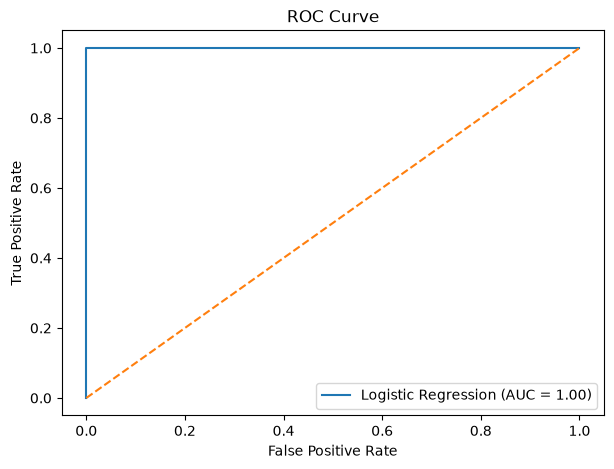

In [25]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.show()

In [26]:
new_customer = pd.DataFrame({
    "Income": [75000],
    "Debt": [12000],
    "Payment_History": [95],
    "Credit_Utilization": [20]
})

new_customer_scaled = scaler.transform(new_customer)

prediction = model.predict(new_customer_scaled)
probability = model.predict_proba(new_customer_scaled)[0, 1]

if prediction[0] == 1:
    result = "Creditworthy"
else:
    result = "Not Creditworthy"

print("Prediction:", result)
print(f"Probability of being creditworthy: {probability * 100:.2f}%")

Prediction: Creditworthy
Probability of being creditworthy: 98.33%


In [ ]:
# Conclusion

In this project, a machine learning classification model was developed
to predict an individual's creditworthiness using financial information.

The dataset included features such as:

- Income
- Debt
- Payment History
- Credit Utilization

The data was explored and visualized to understand the relationship between
financial features and creditworthiness.

The features were standardized using StandardScaler and a Logistic Regression
classification model was trained.

The model was evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

A confusion matrix and ROC curve were also created to evaluate the model's
classification performance.

Finally, the trained model was used to predict the creditworthiness of a
new customer based on their financial information.

This project demonstrates how machine learning classification can be applied
to credit-scoring problems using financial history.